# Lumped JPAs, capacitively and inductively coupled (twpa-sim `jpa` / `jpa_inductive`), rebuilt in the Quantcore PDK

**What it is.** The simplest Josephson parametric amplifier: one junction shunted by a capacitor, a lumped LC mode
whose inductance is the junction's L_J(I). Pumped through the signal port near resonance, the junction's Kerr
nonlinearity mixes pump, signal and idler (four-wave mixing) and amplifies in reflection (Eichler & Wallraff,
EPJ Quantum Technology 1, 2 (2014)). Two ways to couple the mode to the 50 Ω line: a series capacitor, or a shared
(pickup) inductance.

**Source.** twpa-sim (S. Mandal, MIT), `src/twpa/layout/generate.py`, families `jpa` and `jpa` with
`inductive_coupler=true` (`examples/layout/jpa.json`, `jpa_inductive.json`), on its *illustrative* two-metal
overlap process (`jj_overlap_illustrative.json`: J_c 5 µA/µm², C_J 60 fF/µm², MIM 1 fF/µm²): a 2 × 2 µm junction
(I_c 20 µA, C_J 240 fF) shunted by a 12 × 12 µm MIM capacitor (144 fF); the inductive variant adds an M1 pickup loop
(gap 8, height 10, length 40 µm). Cloned read-only into `build/external/twpa-sim` (rev 05abc83), never run.

**This is a Quantcore-PDK rebuild**: the topology (junction ∥ shunt C to ground, capacitive or inductive coupling to
a one-port line) on our process.

| | twpa-sim source | Quantcore rebuild (why) |
|---|---|---|
| junction | 2 × 2 µm overlap JJ, I_c 20 µA, C_J 240 fF | the **largest PDK trilayer junction** (2 × 2 µm fingers): I_c 0.65 µA, L_J 0.51 nH, C_J 200 fF (J_c is the PDK's qubit rule); flagged `pdk_rn` |
| shunt C | 12 × 12 µm MIM, 144 fF (no MIM on our process) | a planar interdigital capacitor island–ground (`LumpedJpa`), ≈ 0.9 pF so that f0 ≈ 7 GHz |
| f0 | ≈ 63 GHz (illustrative values) | ≈ 6–7 GHz (a usable JPA band with the PDK junction) |
| capacitive coupling | external (twpa-sim: "coupling and bias circuitry is external") | KQC `FingerCapacitorSquare` snapped to the island lead |
| inductive coupling | M1 pickup loop, mutual M (needs EM extraction) | a **tapped inductance**: the junction's ground side lands on a strip shared with the signal line (galvanic, its L is analytic: geometry + Nb kinetic inductance) |
| chip | none (device cells) | 7.5 × 7.5 mm PDK die, two `BondPad`s 100 µm from the edge |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 7.5 mm die, one bond pad per JPA, the capacitive JPA's feed with its
coupling capacitor, the two lumped JPAs (the nonlinear elements: one junction each, shunted by an interdigital
capacitor), the inductive JPA's feed to its tap, and then the whole chip (the sim groups, the save). Then the same
steps as the Flow strip of the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM** (the amplifier's circuit
models, their plots, one change by hand) → **Simulate** (export to HFSS, the Q3D C-matrix of each JPA, the eigenmode
simulation with the junction as a lumped inductor, the full-wave run of the capacitive JPA on the eigenmode's mesh
settings) → **Results** (the eigenmodes plotted, f0, κ and the Kerr read off, FEM against the LOM, a feedback step and
the iteration to a frequency target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `twpa_sim_jpa.v1.ipynb`; both save the same
`twpa_sim_jpa.json`.

## Setup

The imports, the output folder and the switches. `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_values, c_fF
from _amplifiers import jpa_mode, reflection_values   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.layouts.others.amplifiers import LumpedJpa, drawn_junction_values
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip that means: the 7.5 mm die with the QCT frame, the two bond pads 100 µm from the west and
east edges, and the largest junction the PDK finger range allows (a 2 × 2 µm trilayer, I_c 0.65 µA): far outside the
qubit R_n window (flagged `pdk_rn`, not retuned) and far below twpa-sim's illustrative 20 µA, so the shunt capacitor
is planar and ≈ 0.9 pF for a 6–7 GHz mode (the PDK has no MIM layer).

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame |
| 2 | one `BondPad` per JPA: `P_C` (west, the capacitive one), `P_L` (east, the inductive one) |
| 3 | the capacitive JPA's feed: its coupling capacitor `CC` and the 50 Ω line `L_C` from `P_C` to it |
| 4 | the nonlinear elements: the junction (drawn against the source's), then the two `LumpedJpa`s, `JC` snapped to the capacitor and `JL` with its inductive tap |
| 5 | the routing: the inductive JPA's feed `L_L`, pad → tap |
| 6 | the whole chip: the sim groups, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip: a standard 7.5 × 7.5 mm Quantcore die, on which the PDK draws the
**QCT frame** — the L dicing markers, the corner marker areas, the chip boundary and the device ID (`name_chip`
"LJPA") on a free edge. `YC` and `YL` are the heights of the two JPAs: the capacitive one north, the inductive one
south.

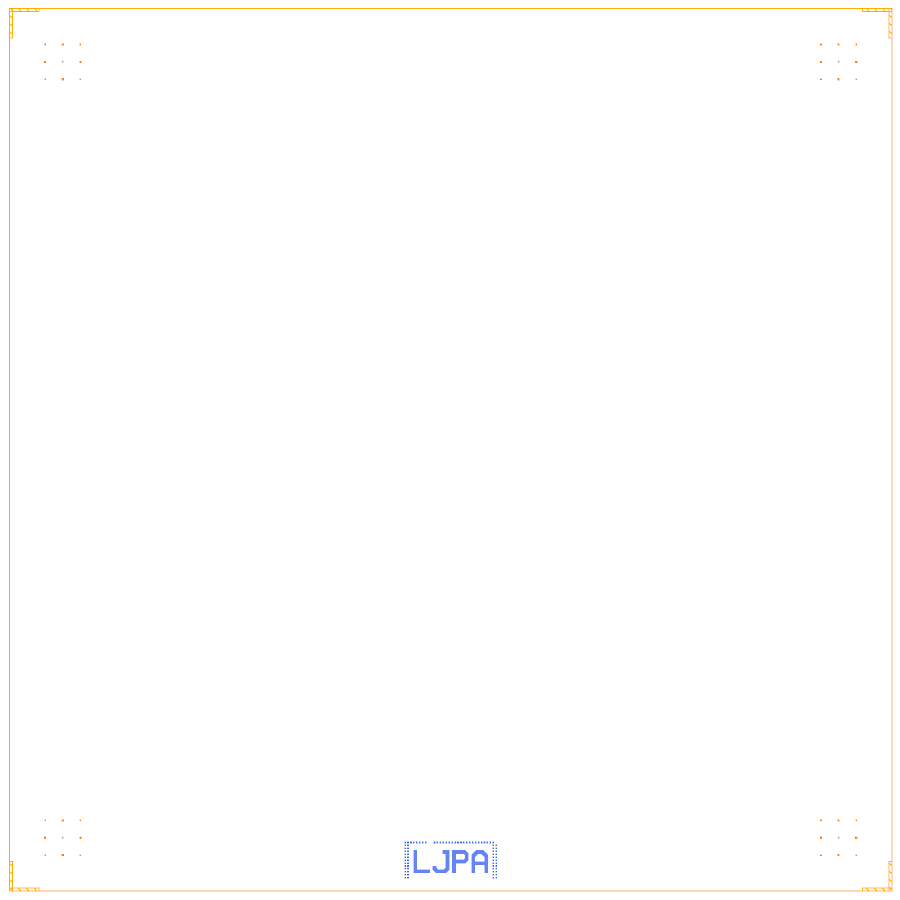

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s1_die.png')

In [5]:
W = H = 7500
YC, YL = 4600, 2900                              # capacitive JPA (north), inductive JPA (south)
d = Designer("twpa_sim_jpa", box=(0, 0, W, H), chip={"name_chip": "LJPA"}, live=LIVE)
layout_step(d, OUT / "twpa_sim_jpa_s1_die.png", size=(900, 900), width=400)

## Design 2 · Bond pads (the 100 µm rule)
One `BondPad` per JPA (each JPA is a one-port amplifier used in reflection): the capacitive one fed from the west
edge, the inductive one from the east edge, so the content sits centred; `edge="auto"` puts each pad's outer
etch 100 µm from the die edge.

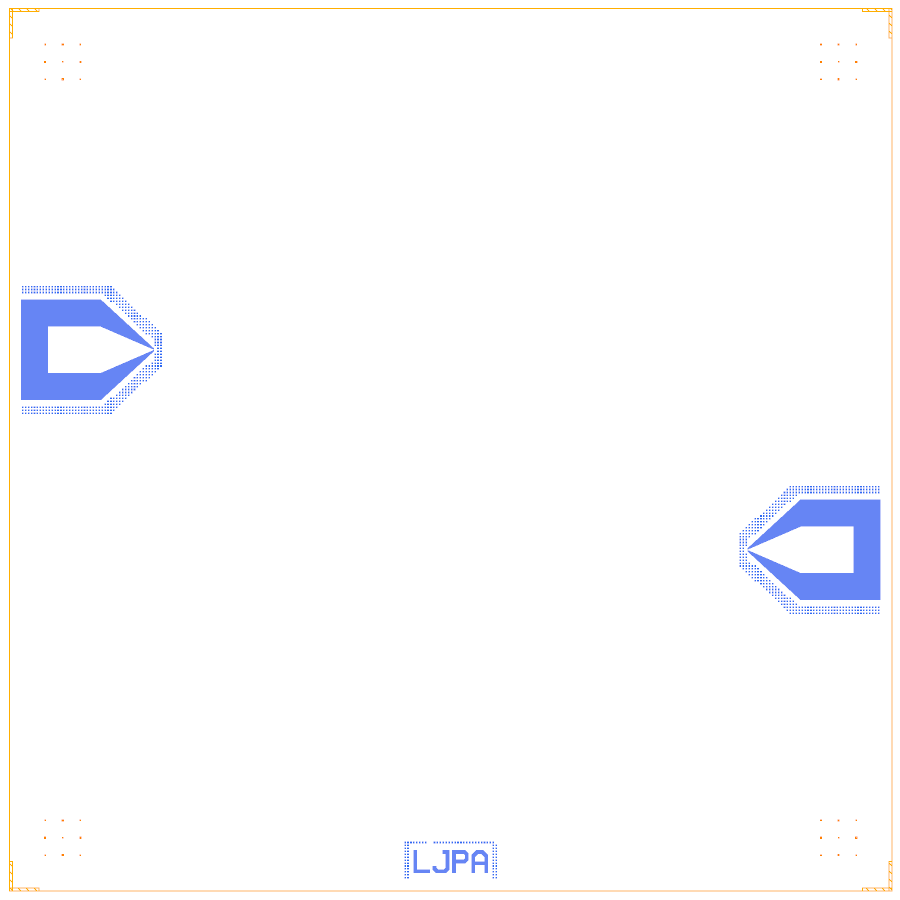

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_C`, `P_L`.

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s2_pads.png')

In [6]:
with d.batch():
    d.add("P_C", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_L", "BondPad", at=(7100, YL), rot=90, edge="auto")
layout_step(d, OUT / "twpa_sim_jpa_s2_pads.png", size=(900, 900), width=400)

## Design 3 · The capacitive JPA's feed: the coupling capacitor and its line

Each JPA is used in reflection, through its own pad. The capacitive one couples to its line through `CC`, KQC's
`FingerCapacitorSquare` (12 fingers × 80 µm, 5 µm wide, 3 µm gaps); `L_C` is the plain 50 Ω feed from `P_C` to the
capacitor's port `a`. Both need nothing else on the chip, so they come first; the JPA itself is snapped to the
capacitor's other port in Design 4. The inductive JPA has no capacitor: its feed ends on the JPA's tap (Design 5).

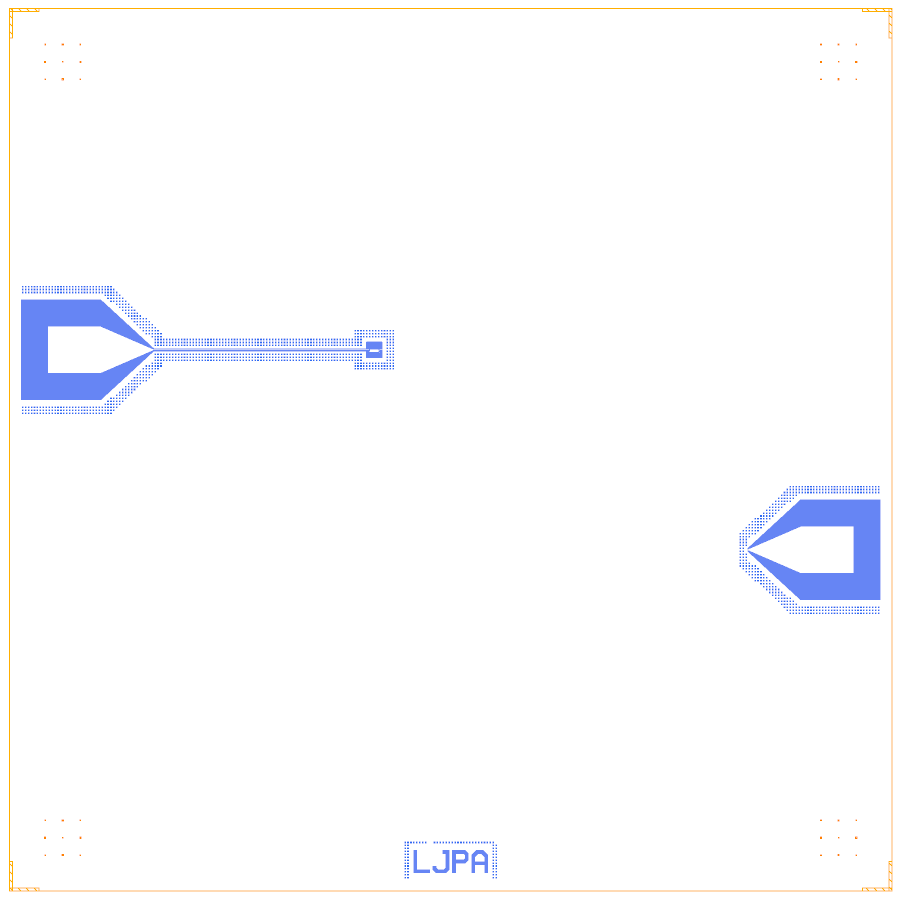

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `CC` and 1 route(s) `L_C`.

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s3_feed.png')

In [7]:
with d.batch():
    cc = d.add("CC", "FingerCapacitorSquare", at=(3100, YC), finger_number=12, finger_length=80, finger_width=5,
               finger_gap=3)
    d.route("L_C", "P_C.a", "CC.a")
layout_step(d, OUT / "twpa_sim_jpa_s3_feed.png", size=(900, 900), width=400)

## Design 4 · The nonlinear elements: the two lumped JPAs

**The junction.** twpa-sim's illustrative 2 × 2 µm overlap junction (I_c 20 µA) is beyond the PDK rule: the largest
the PDK finger range allows is a 2 × 2 µm trilayer (`BIG_JJ`). `drawn_junction_values` gives its L_J and C_J from the
PDK; the table puts it next to the source's (and shows why twpa-sim's own LC is ≈ 63 GHz). `JUNCTION` goes on each
instance: the LOM uses it, the DRC flags its `pdk_rn`, the eigenmode job draws it as a lumped inductor.

**The JPAs.** `LumpedJpa`: an island (20 µm spine, `shunt_fingers` fingers per side, 150 µm long, 4 µm wide, 4 µm
gaps) in its own pocket; the ground fingers hang from the pocket walls, so the island–ground IDC is the shunt C. The
trilayer junction bridges a 16 µm gap at the junction end (window 32 × 16 µm; its fingers land on a 2 µm landing
head).

* `JC` (capacitive): the island's lead is the port `signal`, snapped to the coupling capacitor's port `b` (Design 3),
  so the JPA sits where the capacitor ends. The junction is at the far end, to the pocket wall.
* `JL` (inductive): the lead ends on a tap pad tied to the pocket floor by a 152 µm × `tap_width` strip; the
  junction joins the tap pad and the island. The strip is the inductance the line and the JPA loop share.

The table gives the analytic shunt C and the tap's inductance. The first picture is the chip so far, the second zooms
on the capacitive JPA (the coupling capacitor, the island's fingers, the junction).

In [8]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}
LJ, CJ, _ = drawn_junction_values("Quantcore Junction", BIG_JJ)
JUNCTION = {"Lj_nH": LJ, "Cj_fF": CJ}
SRC = {"Ic_uA": 20.0, "Cj_fF": 240.0, "C_mim_fF": 144.0}         # twpa-sim illustrative process, 2 × 2 µm
lj_src = amp.lj_from_ic(SRC["Ic_uA"] * 1e-6)
f_src = 1 / (2 * np.pi * np.sqrt(lj_src * (SRC["Cj_fF"] + SRC["C_mim_fF"]) * 1e-15)) / 1e9
show_md(table_md(["junction", "I_c (µA)", "L_J (nH)", "C_J (fF)", "R_n (kΩ)"], [
    ["drawn: trilayer 2.0 × 2.0 µm (PDK max)", amp.ic_from_lj(LJ * 1e-9) * 1e6, LJ, CJ, rn_from_lj(LJ) / 1e3],
    ["twpa-sim illustrative 2 × 2 µm", SRC["Ic_uA"], lj_src * 1e9, SRC["Cj_fF"], rn_from_lj(lj_src * 1e9) / 1e3]])
    + f"\n\ntwpa-sim's own LC: f0 = 1/2π√(L_J (C_J + C_MIM)) ≈ {f_src:.0f} GHz (illustrative, not a design target).")

| junction | I_c (µA) | L_J (nH) | C_J (fF) | R_n (kΩ) |
|---|---|---|---|---|
| drawn: trilayer 2.0 × 2.0 µm (PDK max) | 0.6516 | 0.5051 | 200 | 3.375 |
| twpa-sim illustrative 2 × 2 µm | 20 | 0.01646 | 240 | 0.11 |

twpa-sim's own LC: f0 = 1/2π√(L_J (C_J + C_MIM)) ≈ 63 GHz (illustrative, not a design target).

| JPA | C_shunt (fF, analytic) | L_tap (nH) | of which kinetic (pH) |
|---|---|---|---|
| JC | 883.8 | – | – |
| JL | 883.8 | 0.1276 | 2.2 |

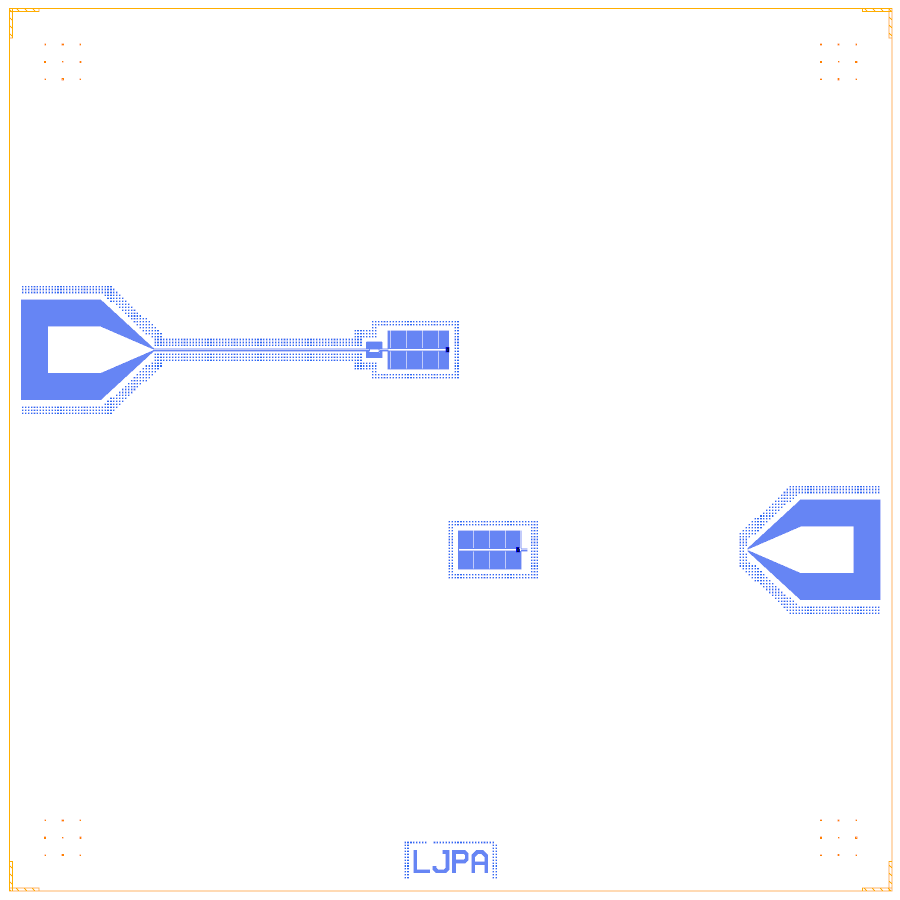

**On the chip so far:** 2 pads · 0 qubits · 3 other components · 1 routes · 0 declared couplings. **This step added** 2 component(s) `JC`, `JL`.

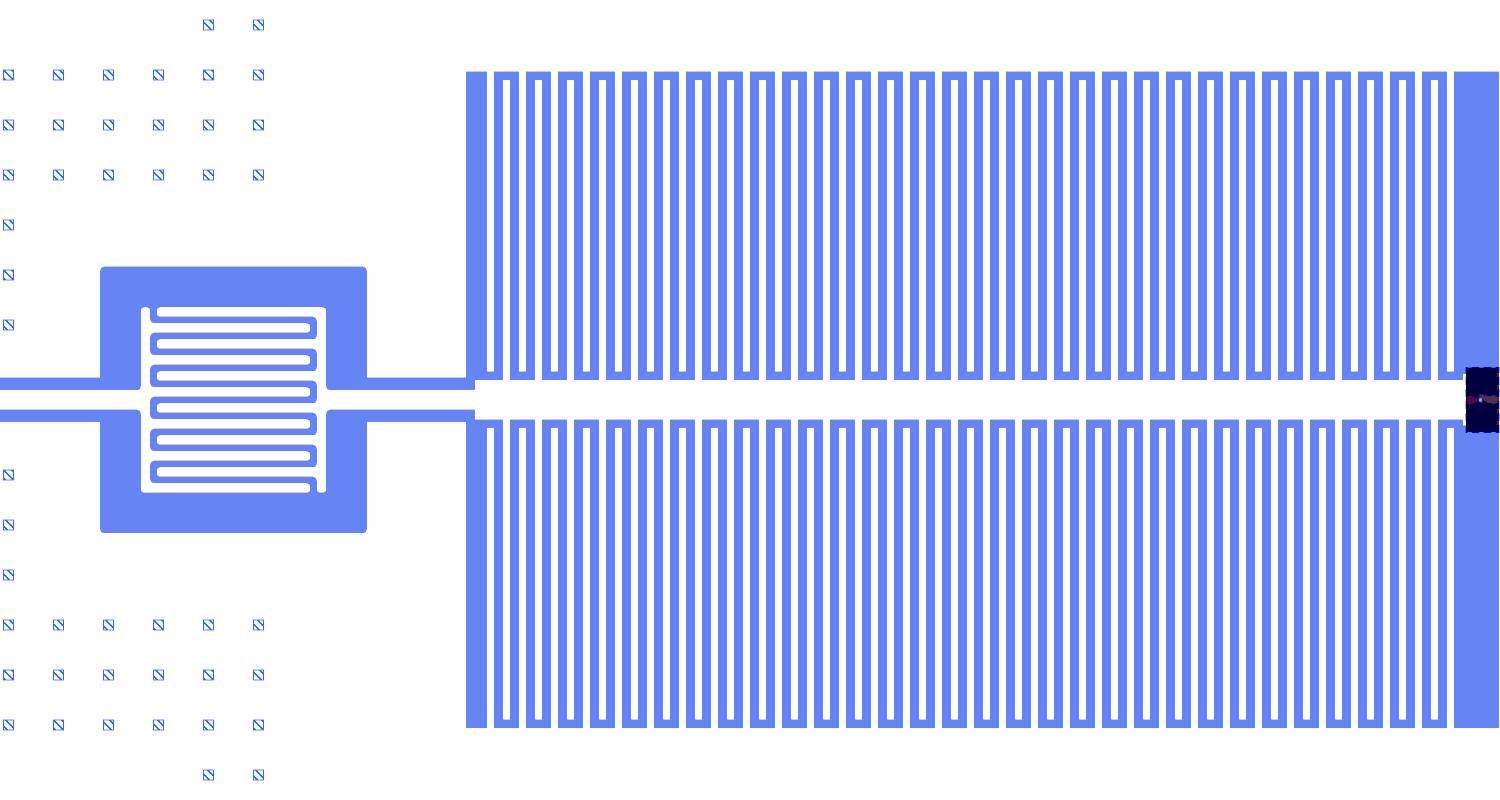

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s4_capacitive.png')

In [9]:
SHUNT = dict(shunt_fingers=30, finger_length=150, finger_width=4, finger_gap=4)
with d.batch():
    jc = d.add("JC", "LumpedJpa", snap="signal", to="CC.b", junction=JUNCTION, junction_params=BIG_JJ, **SHUNT)
    jl = d.add("JL", "LumpedJpa", at=(4400, YL), rot=180, coupling="inductive", tap_width=8, junction=JUNCTION,
               junction_params=BIG_JJ, **SHUNT)
show_md(table_md(["JPA", "C_shunt (fF, analytic)", "L_tap (nH)", "of which kinetic (pH)"], [
    ["JC", LumpedJpa.qcc_values(jc.spec["params"])["C_shunt_fF"], None, None],
    ["JL", LumpedJpa.qcc_values(jl.spec["params"])["C_shunt_fF"],
     LumpedJpa.qcc_values(jl.spec["params"])["L_tap_nH"], 1e3 * LumpedJpa.qcc_values(jl.spec["params"])["L_tap_k_nH"]]]))
layout_step(d, OUT / "twpa_sim_jpa_s4_jpas.png", size=(900, 900), width=400)
xcc, ycc = port_xy(d, "CC.a")                    # the capacitive JPA starts at its coupling capacitor
snap(d, OUT / "twpa_sim_jpa_s4_capacitive.png", box=(xcc - 50, ycc - 200, xcc + 700, ycc + 200), size=(1500, 800),
     width=600)

## Design 5 · Routing: the inductive JPA's feed
The plain 50 Ω feed `L_L` from `P_L` to the inductive JPA's tap (`JL.signal`); the capacitive JPA's feed `L_C` came in
Design 3. The tap strip it lands on is the inductance the line and the JPA share.

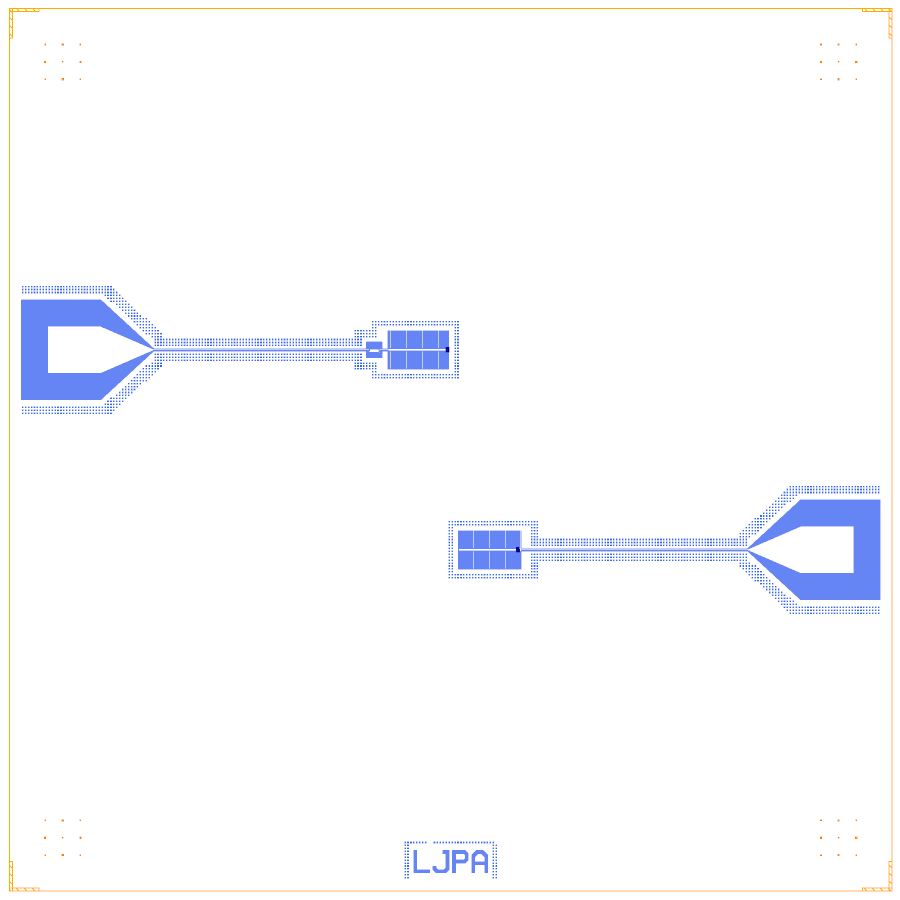

**On the chip so far:** 2 pads · 0 qubits · 3 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `L_L`.

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s5_feed_l.png')

In [10]:
with d.batch():
    d.route("L_L", "P_L.a", "JL.signal")
layout_step(d, OUT / "twpa_sim_jpa_s5_feed_l.png", size=(900, 900), width=400)

## Design 6 · The whole chip: the sim groups, the save

**Sim groups.** `jpa_c` (the capacitor and the capacitive JPA) and `jpa_l` (the inductive JPA), each with a 100 µm
margin, for a Q3D C-matrix and an eigenmode job; the feeds are cut at the box edges. The design sets no targets
(Results 4 puts one on a copy).

**No centring.** The two JPAs are fed from opposite edges, so the content is centred as drawn (Check 1's
`pdk_report` measures it).

**Save.** `save_design` writes `twpa_sim_jpa.json` and compares it with the file it replaces (the previous run's,
e.g. the `.v1` notebook's): it should say *same design*. The picture is the whole chip.

**Same design as before:** `examples/designs/amplifiers/twpa_sim_jpa.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer twpa_sim_jpa: 5 instances, 2 routes, live=False> → examples\designs\amplifiers\twpa_sim_jpa.json


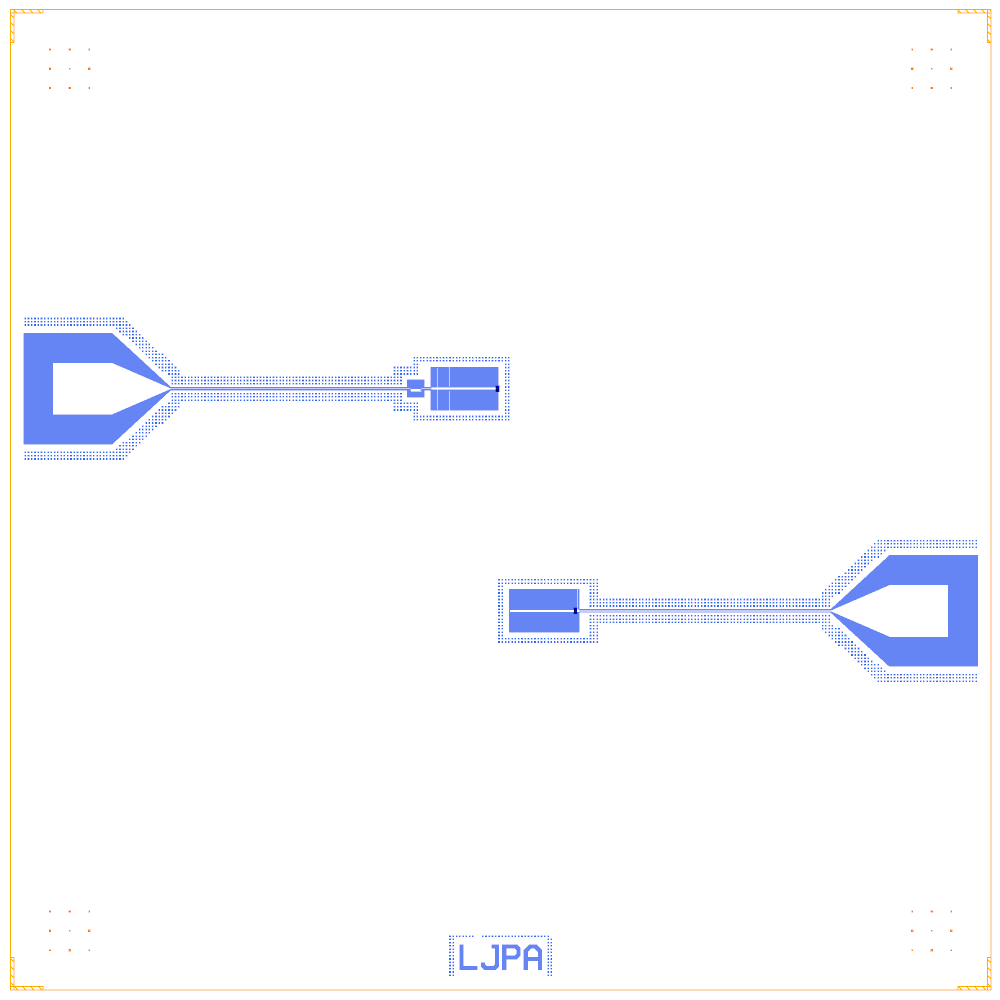

**On the chip so far:** 2 pads · 0 qubits · 3 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/twpa_sim_jpa_s6_chip.png')

In [11]:
d.sim_group("jpa_c", ["CC", "JC"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("jpa_l", ["JL"], margin_um=100, analyses=["q3d_cmatrix", "eigenmode_epr"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "twpa_sim_jpa.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "twpa_sim_jpa_s6_chip.png", size=(1000, 1000), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
`dangling_port` warnings on `squid_a` / `squid_b` are the junction ends (FEM ports); `pdk_rn` flags each junction's
R_n ≈ 3.4 kΩ (qubit window 40–50 kΩ) — an amplifier junction, kept as designed.

Expected here (from the v1 run): no errors, four `dangling_port` warnings (`squid_a`, `squid_b` of `JC` and `JL`) and
`pdk_rn` on `JC` and `JL` (L_J 0.505 nH); content centre − die centre (+0, +0) µm.

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip box
and the frame: **errors** would block fab, **warnings** are layout hints, **PDK design warnings** (`pad_edge`,
`pdk_rn`, …) flag a PDK margin and are never fixed by retuning. `pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
`JC`: island node with C_shunt and the JJ to ground; `CC`'s π network to the pad node (50 Ω). `JL`: island node
(C_shunt), the JJ island–tap, the tap node with L_tap (strip, Grover + Nb kinetic inductance) and a small pad C to
ground; the pad's 50 Ω sits on the tap — the tapped-inductor coupling.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit models

Two views of each JPA: QuCat's normal mode of its lumped circuit (f0, κ through the 50 Ω pad, the anharmonicity = the
self-Kerr per photon), then the Kerr-pumped gain of the capacitive one. The plot is in LOM 2.

QuCat normal modes (first order: f, κ through the 50 Ω pad, anharmonicity = self-Kerr K per photon).

In [ ]:
groups = {"capacitive": ["P_C", "L_C", "CC", "JC"], "inductive": ["P_L", "L_L", "JL"]}
res = simulate_groups(d, groups, max_modes=1)
for g, r in res.items():
    display(Markdown(f"**{g}**\n\n" + modes_md(r)))
MODE = {g: r.modes[0] for g, r in res.items()}
show_md(table_md(["JPA", "f0 (GHz)", "κ/2π (MHz)", "Q_ext", "|K|/2π (MHz)"],
                 [[g, m.f_GHz, m.kappa_MHz, m.f_GHz * 1e3 / m.kappa_MHz, abs(m.anharmonicity_MHz)]
                  for g, m in MODE.items()]))

**Gain vs pump** (Kerr / current-pumped paramp, `analysis.amplifiers`): the pump at Δ = ω_p − ω0 below resonance
(K < 0) holds n photons, n[(κ/2)² + (Δ − K n)²] = κ Φ_in; the linearised response has δ0 = ω0 − ω_p + 2Kn and
g = K n. Δ = −0.9·√3 κ/2 stays just inside the monostable regime (bistability starts at |Δ| = √3 κ/2): the gain
rises with the pump power to a maximum, then falls as the pump detunes the mode past the signal.

In [ ]:
m = MODE["capacitive"]
kappa, kerr = 2 * np.pi * m.kappa_MHz * 1e6, -2 * np.pi * abs(m.anharmonicity_MHz) * 1e6  # junction: K < 0
delta_p = -0.9 * np.sqrt(3) * kappa / 2
flux_c = (kappa / 2) ** 3 / abs(kerr) / kappa      # photon flux scale where K n ~ κ/2
fluxes = np.geomspace(0.05, 2.5, 80) * flux_c
peak = []
for fl in fluxes:
    n = amp.kerr_pump_photons(delta_p, kerr, kappa, 0.0, fl)[0][0]
    peak.append(float(amp.db(amp.kerr_gain(np.linspace(-2, 2, 801) * kappa, delta_p, kerr, kappa, 0.0, n)).max()))
p_dbm = 10 * np.log10(fluxes * amp.H_PLANCK * (m.f_GHz * 1e9 + delta_p / 2 / np.pi) / 1e-3)
i = int(np.argmax(peak))
show_md(f"Peak gain {peak[i]:.1f} dB at {p_dbm[i]:.1f} dBm (single-mode Kerr model, undepleted pump).")

## LOM 2 · The model in a plot

The capacitive JPA's peak signal gain against the pump power at the device (the Kerr model of LOM 1, the pump detuned
just inside the monostable regime): the gain rises with the pump to its maximum, then falls as the pump detunes the
mode past the signal.

In [ ]:
plot(OUT / "twpa_sim_jpa_gain.png", [(p_dbm, peak, "peak signal gain")], "pump power at the device (dBm)",
     "gain (dB)", f"capacitive JPA (Kerr pumped): f0 {m.f_GHz:.3f} GHz, κ/2π {m.kappa_MHz:.1f} MHz, "
     f"|K|/2π {abs(m.anharmonicity_MHz):.2f} MHz");

## LOM 3 · One change by hand: the inductive tap
Before the FEM, a design step by hand. One property: the tap strip width 8 → 4 µm (more shared inductance, stronger
coupling: Q_ext drops). The change is made on a copy (`design_copy`: a non-live Designer that never writes over the
design file), so the chip saved in Design 6 stays as it is and nothing is saved again. From the v1 run: L_tap 0.128 →
0.150 nH, Q_ext 71 → 54 (f0 unchanged).

In [ ]:
before = MODE["inductive"]
d2 = design_copy(DESIGN)                         # a non-live copy of the saved design (never saved over it)
d2["JL"].set(tap_width=4)
after = simulate_groups(d2, {"inductive": groups["inductive"]}, max_modes=1)["inductive"].modes[0]
show_md(table_md(["tap width", "L_tap (nH)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"], [
    [f"{w} µm", LumpedJpa.qcc_values({**jl.spec["params"], "tap_width": w})["L_tap_nH"], mm.f_GHz, mm.kappa_MHz,
     mm.f_GHz * 1e3 / mm.kappa_MHz] for w, mm in ((8, before), (4, after))]))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS
A Q3D C-matrix job of each JPA (island, coupling capacitor, tap pad) and an eigenmode job with the junction as a
lumped inductor at `squid_a` / `squid_b`. The lines leaving each box end in 50 Ω, so the mode's Q gives κ.

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["jpa_c", "jpa_l"])
jobs_eig = export_sims(DESIGN, ["jpa_c", "jpa_l"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitances of `jpa_c` (from the v1 run's job table the nets are `JC.island` and `L_C`: the capacitor's outer
side carries the feed) and of `jpa_l` (`JL.island` and `JL.tap`). Each net is named after its LOM node, so the matrix
goes straight into the circuit (Results 3). `fem_stage` solves each job with `RUN_FEM`, else loads its kept results,
else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The two boxes in HFSS eigenmode: each junction is a lumped inductor (L_J 0.505 nH, the instance's junction) between
`squid_a` and `squid_b`, and the feed leaving each box ends in 50 Ω, so the JPA mode's Q gives κ. pyEPR (run inside
qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) adds the junction participation p_J and the mode's self-Kerr.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh** itself
to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group
and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode nearest the LOM's f0 (the
LOM's f0 itself before the eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above it.

A JPA is read in **reflection**: the resonance is in the phase of S11 at the signal port, not a notch in S21 (the fit
`driven_md` lists is made for hangers, so it may find none). Results 2 reads f0 and κ off S11 with
`reflection_values` (`analysis.amplifiers.resonance`: the steepest phase) from the Touchstone file the solve leaves
in the job folder; the kept copy in `fem/` holds `results.json` only and the next export empties the job folder, so
S11 is read in the run that solved it.

Only the capacitive JPA gets a driven job: the inductive one is so strongly coupled (from the v1 run: Q_ext ≈ 71) that
the helper's mode pick (Q > 100) would not take its mode and would set the sweep on another one; its eigenmode Q gives
its κ.

In [ ]:
f_jc = MODE["capacitive"].f_GHz                  # the LOM's f0 of the capacitive JPA (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "jpa_c", jobs_eig["jpa_c"][0], keep_eig["jpa_c"], f_guess=f_jc)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["jpa_c"]:
    display(Markdown(driven_md(keep_drv["jpa_c"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the JPA mode, a junction shunted by a capacitor), with the LOM's
f0 of each JPA as a dashed line. The tables list the modes and the pyEPR values.

In [ ]:
plot_eigenmodes(keep_eig, OUT / "twpa_sim_jpa_eigenmodes.png", lom={"JC": MODE["capacitive"].f_GHz,
                                                                    "JL": MODE["inductive"].f_GHz})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each JPA's mode in the LOM's terms: `jpa_mode` takes the solved mode nearest the LOM's f0 with Q > 10 (a JPA is
strongly coupled), κ = f / Q_ext, p_J and the self-Kerr from pyEPR. The driven run adds the capacitive JPA's f0 and κ
from the phase of S11 at its feed (`reflection_values`), when the trace is in the job folder (the run that solved it).

In [ ]:
SIM = {"capacitive": "jpa_c", "inductive": "jpa_l"}   # the LOM groups of LOM 1 → their sim groups
fem_jpa = {g: jpa_mode(keep_eig[s], MODE[g].f_GHz) for g, s in SIM.items()}   # {} for a JPA without results
refl = reflection_values("L_C", keep_drv["jpa_c"], jobs_drv["jpa_c"][0])     # S11 of the capacitive JPA's feed
vals = [[g, e["f_GHz"], e["Q_ext"], e["kappa_MHz"], e.get("kerr_MHz"), e.get("p_J")] for g, e in fem_jpa.items() if e]
if vals:
    show_md(table_md(["JPA (eigenmode)", "f (GHz)", "Q_ext", "κ/2π (MHz)", "self-Kerr (MHz)", "p_J"], vals))
if refl:
    show_md(f"Driven S11 at `L_C`: f0 {refl['f_GHz']:.4f} GHz, κ/2π {refl['kappa_MHz']:.2f} MHz (`{refl['file']}`)")
if not vals:
    print("No eigenmode results yet (RUN_FEM = True): this table would list each JPA mode's f, Q_ext, κ, self-Kerr "
          "and p_J (pyEPR); the driven run adds the capacitive JPA's f0 and κ from S11.")

## Results 3 · FEM against the LOM

Per JPA: **the LOM on the Q3D C-matrix** (`fill` replaces the capacitance estimates of the JPA's components by the
C-matrix, matched by net name, and the same LOM runs again), **the eigenmode** (Results 2: f0, κ and the Kerr against
QuCat's anharmonicity) and, for the capacitive one, **the driven S11**. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

cmp_rows = []
for g, s in SIM.items():
    lom_g, fem_g = MODE[g], fem_jpa[g]
    if keep_q3d[s]:
        on_q3d = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[s]), max_modes=1).modes[0]
        cmp_rows += [(f"{g}: f0 (GHz)", lom_g.f_GHz, on_q3d.f_GHz, "LOM on the Q3D C-matrix"),
                     (f"{g}: κ (MHz)", lom_g.kappa_MHz, on_q3d.kappa_MHz, "LOM on the Q3D C-matrix")]
    if fem_g:
        cmp_rows += [(f"{g}: f0 (GHz)", lom_g.f_GHz, fem_g["f_GHz"], "eigenmode"),
                     (f"{g}: κ (MHz)", lom_g.kappa_MHz, fem_g["kappa_MHz"], "eigenmode, f / Q_ext")]
        if fem_g.get("kerr_MHz") is not None:
            cmp_rows.append((f"{g}: |K| (MHz)", abs(lom_g.anharmonicity_MHz), abs(fem_g["kerr_MHz"]),
                             "pyEPR self-Kerr against QuCat's anharmonicity"))
if refl:
    cmp_rows += [("capacitive: f0 (GHz)", MODE["capacitive"].f_GHz, refl["f_GHz"], "driven S11"),
                 ("capacitive: κ (MHz)", MODE["capacitive"].kappa_MHz, refl["kappa_MHz"], "driven S11")]
if cmp_rows:
    display(Markdown(fem_vs_lom_md(cmp_rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each JPA's f0, κ and Kerr from the LOM next to the "
          "LOM on the Q3D C-matrix, the eigenmode and (capacitive) the driven S11, with the difference in %.")

## Results 4 · Feedback: one step towards a target

twpa-sim states no frequency (its values are illustrative: ≈ 63 GHz), so this notebook sets one as an exercise: **the
capacitive JPA at 6.80 GHz**, where the LOM puts the inductive one (from the v1 run: JC 6.592 GHz, JL 6.802 GHz), so
the two couplings can be compared at one frequency. Tolerance ± 5 MHz (well inside κ, ≈ 40 MHz). The target goes on a
copy (`target_copy` → `build/twpa_sim_jpa_target.json`).

`loop.feedback` tunes qubit–readout pairs; a JPA has none, so the feedback is the LC rule on one knob,
`JC.finger_length` (150 µm; `JL` keeps its fingers): f ∝ (C_shunt + C_J + …)^−1/2 and C_shunt ∝ the finger overlap
ℓ − gap, so f ∝ ℓ^p with the prior p = −½ · C_shunt / (C_shunt + C_J) · ℓ / (ℓ − gap) ≈ −0.42. By the rule the fingers
get ≈ 12 µm shorter (from the v1 run's LOM). The coupling capacitor stays, so κ changes a little with the mode's C.
When an eigenmode is kept, the LOM is first scaled by FEM / LOM of f0 (`SCALE`).

In [ ]:
from quantcore_circuits.layouts.others.keepout import full_params

F_T, F_TOL = 6.80, 0.005                         # the exercise target for JC and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"JC": {"f_GHz": F_T}})
F_FEM = fem_jpa["capacitive"].get("f_GHz")
SCALE = F_FEM / MODE["capacitive"].f_GHz if F_FEM else 1.0   # FEM / LOM of JC's f0 (1: the LOM alone)
FPJ = full_params(LumpedJpa, jc.spec["params"])  # JC's parameters, the cell defaults filled in
K0, GAP = float(FPJ["finger_length"]), float(FPJ["finger_gap"])
CS = LumpedJpa.qcc_values(jc.spec["params"])["C_shunt_fF"]
P0 = -0.5 * CS / (CS + CJ) * K0 / (K0 - GAP)     # f ∝ C^-1/2, C ≈ C_shunt + C_J, C_shunt ∝ the finger overlap
F_NOW = SCALE * MODE["capacitive"].f_GHz
K1 = rule_step(K0, F_NOW, F_T, P0)
show_md(f"**JC:** now {F_NOW:.4f} GHz ({'FEM' if F_FEM else 'LOM'}), target {F_T} ± {F_TOL} GHz → shunt fingers "
        f"{K0:g} → **{K1:.1f} µm** (f ∝ ℓ^{P0:.2f})")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets JC's finger length, its LOM runs (× `SCALE`), and the next step
uses the exponent of the last two points (a secant), until JC is within 5 MHz of 6.80 GHz or `MAX_ITER` steps are
made; the fingers stay within 40–300 µm. Each revision is a design file (`build/twpa_sim_jpa_rev<k>.json`). With
`RUN_FEM = True` each revision's `jpa_c` eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and
the loop closes on the FEM's f0. The table shows each step's f0 against the target and the knob it moved; the plot the
residual in tolerances (on target below 1).

In [ ]:
def f_of(k, it):
    """Revision it: JC's shunt fingers k µm long; JC's f0 on the LOM (× SCALE), or from its own eigenmode (RUN_FEM)."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["JC"].set(finger_length=k)
    path = d2.save(Path("build") / f"twpa_sim_jpa_rev{it}.json")
    f_k = simulate_groups(d2, {"capacitive": groups["capacitive"]}, max_modes=1)["capacitive"].modes[0].f_GHz
    if RUN_FEM:
        job = export_sims(path, ["jpa_c"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        e = jpa_mode(fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["jpa_c"], SCALE * f_k)
        if e:
            return e["f_GHz"], path
    return SCALE * f_k, path


history = rule_iterate(f_of, "JC.f_GHz", "JC.finger_length", K0, F_T, F_TOL, P0, max_iter=MAX_ITER,
                       start=(F_NOW, DESIGN_T), fem=bool(RUN_FEM), bounds=(40.0, 300.0))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "twpa_sim_jpa_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design JSON saved in Design 6 is the deliverable: `qcc build examples/designs/amplifiers/twpa_sim_jpa.json`, `qcc
mask …` (PDK fab layers, rounding, cheese band).

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
show_md(f"cheese: {fab.get('cheese_source')}; written: " + ", ".join(f"{k} {n}" for k, n in fab["written"].items()))

## Fab 2 · Snapshots
The full die; the capacitive JPA (coupling capacitor, island IDC, junction); the inductive JPA's tap and junction;
twpa-sim's own rendering of its layout families (`docs/assets/layout-families.png`) when the clone is present.

In [ ]:
show_snapshot(d, OUT / "twpa_sim_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "twpa_sim_jpa_cap.png", box=(x - 50, y - 200, x + 700, y + 200), size=(1500, 800), width=600)
x, y = port_xy(d, "JL.signal")
show_snapshot(d, OUT / "twpa_sim_jpa_tap.png", box=(x - 130, y - 40, x - 30, y + 180), size=(900, 1000), width=400)
ref = ROOT / "build/external/twpa-sim/docs/assets/layout-families.png"
if ref.exists():
    display(Image(filename=str(ref), width=600))

## Summary
* **Matches the source:** one junction shunted by a capacitor to ground, one-port reflection amplifier, a capacitive
  and an inductive coupling variant.
* **Differs:** planar IDC instead of the MIM capacitor (the PDK has no MIM layer); the PDK trilayer junction (0.65 µA)
  instead of twpa-sim's illustrative 20 µA, so the shunt C is ≈ 0.9 pF for a ≈ 7 GHz mode (twpa-sim's values give ≈ 63
  GHz); the inductive coupling is a galvanic tap (analytic L) instead of a mutual-inductance pickup loop.
* **PDK design warnings:** `pdk_rn` on `JC` and `JL` (R_n ≈ 3.4 kΩ).
* **Not modelled:** higher-order Kerr terms and pump depletion; the IDC's self-resonance (fingers 150 µm ≪ λ).
* **Layout:** built in six segments (die, pads, the capacitive JPA's feed, the two JPAs, the inductive JPA's feed, the
  whole chip); the saved JSON is the v1 notebook's.
* **Feedback:** an exercise target on a copy (JC at 6.80 GHz, the inductive JPA's frequency): the LC rule on JC's
  shunt finger length, iterated with a secant (LOM × FEM/LOM; the revision's eigenmode with `RUN_FEM`).
* **FEM:** the jobs (Q3D, eigenmode, the capacitive JPA's driven run) are exported, not solved (`RUN_FEM = False`):
  run with `RUN_FEM = True` to fill the Simulate and Results cells.